# 2026 — Learned Sparse Attention and Hybrid Local/Global Stacks

**Papers and systems:** DeepSeek-AI, *"DeepSeek-V3.2: Pushing the Frontier of Open Large Language Models"* (arXiv 2512.02556), which introduced **DeepSeek Sparse Attention (DSA)**. Sliding-window/global interleaving: Longformer (2020), Mistral (2023), Gemma 2/3 (2024–25). Through 2026 the frontier open-weight models (DeepSeek-V4, the GLM-5 family, Kimi, MiMo, MiniMax, Nemotron) all handle long contexts by **not letting every token attend to every other token**. They combine learned sparse attention, local attention and linear/SSM layers (notebooks 59, 70) in hybrid stacks, on top of very sparse MoE (64).

### 1. DSA: a lightning indexer picks the keys
A tiny, cheap scorer (few heads, small dimension, ReLU instead of softmax, FP8 in production) rates every past token:

$$I_{t,s} = \sum_{j=1}^{H^I} w_{t,j}\,\operatorname{ReLU}\!\big(q^I_{t,j}\cdot k^I_s\big)$$

The main attention then runs **only over the top-$k$ keys** for each query ($k=2048$ in DeepSeek-V3.2). Core attention cost drops from $O(T^2)$ to $O(Tk)$; the indexer is still $O(T^2)$ but very light.

**Training (as in the report):**
1. **Warm-up:** keep dense attention, freeze the model, and train only the indexer to match the main attention distribution (summed over heads) with a KL loss.
2. **Sparse training:** switch on top-$k$ selection and train everything, keeping the indexer's KL loss on the selected keys.

### 2. Hybrid local/global stacks
Most layers use cheap **sliding-window** attention (each token sees the last $w$ tokens), and a few layers stay **global** (dense, sparse or linear). The local layers handle syntax and nearby context; the global ones handle long-range retrieval.

**Task:** long-context associative recall. 8 key–value pairs are scattered through 128 tokens of filler, and 4 queries at the end each ask for one key's value. The answer is usually far outside any local window.

![Diagram: Learned sparse attention (DeepSeek-V3.2, 2025) and hybrid stacks](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/75_2026_sparse_and_hybrid_attention.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
NK, NV, P, NQ, T_ctx = 16, 16, 8, 4, 128
FILL = NK + NV; QRY = FILL + 1; V = QRY + 1
def batch(B):
    """Filler tokens with P (key, value) pairs at random positions, then NQ queries [QRY, key]."""
    x = torch.full((B, T_ctx), FILL)
    keys = torch.rand(B, NK).argsort(1)[:, :P]; vals = torch.randint(NK, NK + NV, (B, P))
    slots = torch.rand(B, (T_ctx - 2 * NQ) // 2).argsort(1)[:, :P] * 2  # even positions, so pairs never overlap
    x.scatter_(1, slots, keys); x.scatter_(1, slots + 1, vals)
    pick = torch.rand(B, P).argsort(1)[:, :NQ]                            # which keys are asked about
    x[:, -2 * NQ:] = torch.stack([torch.full((B, NQ), QRY), keys.gather(1, pick)], 2).view(B, 2 * NQ)
    return x.to(device), vals.gather(1, pick).to(device)
x, y = batch(1)
print("example (first 40 tokens):", x[0, :40].tolist(), "\n... queries", x[0, -2 * NQ:].tolist(), "-> answers", y[0].tolist())

example (first 40 tokens): [32, 32, 32, 32, 32, 32, 14, 22, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 2, 28, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 3, 26] 
... queries [33, 4, 33, 13, 33, 2, 33, 3] -> answers [23, 17, 28, 26]


In [3]:
class Indexer(nn.Module):
    """DSA lightning indexer: H_I small heads, one shared indexer key, ReLU scores, learned per-head weights."""
    def __init__(self, d, n_heads=2, d_idx=16):
        super().__init__()
        self.h, self.di = n_heads, d_idx
        self.q, self.k, self.w = nn.Linear(d, n_heads * d_idx, bias=False), nn.Linear(d, d_idx, bias=False), nn.Linear(d, n_heads, bias=False)
    def forward(self, x):                                              # -> (B, T, T) index scores
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.h, self.di)
        k = self.k(x)
        s = F.relu(torch.einsum("bthd,bsd->bths", q, k))                # ReLU(q_j . k_s)
        return (self.w(x).unsqueeze(-1) * s).sum(2)                     # sum_j w_{t,j} * ...

def rope(x, base=10000.0):
    """Rotary position embedding on (..., T, d); relative positions make previous-token heads easy to learn."""
    T, d = x.shape[-2], x.shape[-1]
    inv = 1.0 / base ** (torch.arange(0, d, 2, device=x.device).float() / d)
    ang = torch.arange(T, device=x.device).float()[:, None] * inv
    x1, x2 = x[..., ::2], x[..., 1::2]
    return torch.stack([x1 * ang.cos() - x2 * ang.sin(), x1 * ang.sin() + x2 * ang.cos()], -1).flatten(-2)

class Attention(nn.Module):
    """Causal attention in one of three modes: 'dense', 'window' (sliding window w) or 'sparse' (DSA top-k)."""
    def __init__(self, d, n_heads=4, mode="dense", window=16, topk=32):
        super().__init__()
        self.h, self.dh, self.mode, self.window, self.topk = n_heads, d // n_heads, mode, window, topk
        self.qkv, self.o = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False)
        self.indexer = Indexer(d) if mode == "sparse" else None
        self.sparse_on = True                                           # False during the indexer warm-up stage
        self.kl = torch.tensor(0.0)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        q, k = rope(q), rope(k)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dh)          # (B, h, T, T)
        i = torch.arange(T, device=x.device)
        allowed = (i[None, :] <= i[:, None]).expand(B, T, T)            # causal
        if self.mode == "window":
            allowed = allowed & (i[:, None] - i[None, :] < self.window)
        if self.mode == "sparse":
            idx = self.indexer(x).masked_fill(~allowed, float("-inf"))
            if self.sparse_on:
                top = idx.topk(min(self.topk, T), -1).indices           # top-k keys per query
                sel = torch.zeros_like(allowed).scatter_(-1, top, True) & allowed
            else:
                sel = allowed
            # indexer training signal: KL(main attention summed over heads || indexer distribution), on the selected keys
            with torch.no_grad():
                target = scores.detach().masked_fill(~sel.unsqueeze(1), float("-inf")).softmax(-1).sum(1)
                target = target / target.sum(-1, keepdim=True)
            logp = idx.masked_fill(~sel, float("-inf")).log_softmax(-1)
            self.kl = (target * (target.clamp_min(1e-9).log() - logp.masked_fill(~sel, 0))).sum(-1).mean()
            allowed = sel
        # (Real kernels gather only the selected / in-window keys. Masking a dense matrix gives the same result.)
        a = scores.masked_fill(~allowed.unsqueeze(1), float("-inf")).softmax(-1)
        return self.o((a @ v).transpose(1, 2).reshape(B, T, D))

class LM(nn.Module):
    def __init__(self, modes, d=64):
        super().__init__()
        self.emb = nn.Embedding(V, d)                                   # positions come from RoPE inside attention
        self.attn = nn.ModuleList([Attention(d, mode=m) for m in modes])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)) for _ in modes])
        self.n1 = nn.ModuleList([nn.LayerNorm(d) for _ in modes]); self.n2 = nn.ModuleList([nn.LayerNorm(d) for _ in modes])
        self.head = nn.Linear(d, V)
    def forward(self, x):
        h = self.emb(x)
        for a, m, n1, n2 in zip(self.attn, self.mlp, self.n1, self.n2):
            h = h + a(n1(h)); h = h + m(n2(h))
        return self.head(h[:, -2 * NQ + 1::2])                          # predict at each query-key position
    def indexer_kl(self): return sum(a.kl for a in self.attn if a.indexer is not None)

def fit(model, steps, lr=2e-3, params=None, kl_weight=0.0, task_weight=1.0):
    opt = torch.optim.AdamW(params if params is not None else model.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    for s in range(steps):
        x, y = batch(64)
        loss = task_weight * F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1)) + kl_weight * model.indexer_kl()
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    return model

@torch.no_grad()
def accuracy(model):
    model.eval(); x, y = batch(2000); acc = (model(x).argmax(-1) == y).float().mean().item(); model.train(); return acc

## Baselines: dense vs. local-only vs. hybrid
Two layers each. *Local-only* uses a 16-token window in both layers. *Hybrid* uses one local layer, then one global (dense) layer. Same budget for all three (2500 steps). Dense attention sits on a long loss plateau before it discovers the key→value binding, while the local layer in the hybrid makes that binding easy.

In [4]:
results = {}
for name, modes in [("dense (2 global)", ["dense"] * 2), ("local only (w=16)", ["window"] * 2), ("hybrid (1 local + 1 global)", ["window", "dense"])]:
    seed_everything(0); t0 = time.time()
    m = fit(LM(modes).to(device), 2500)
    results[name] = accuracy(m)
    print(f"{name:30s} accuracy {results[name]:.3f}   ({time.time() - t0:.0f}s)")
    if name.startswith("dense"): dense_model = m

dense (2 global)               accuracy 0.971   (88s)


local only (w=16)              accuracy 0.162   (76s)


hybrid (1 local + 1 global)    accuracy 1.000   (91s)


## DeepSeek Sparse Attention: convert the trained dense model
Following the report, start from the trained dense model and add an indexer to every layer:
1. **as-is:** turn on top-$k$ ($k=32$ of up to 128 keys) with an *untrained* indexer
2. **warm-up:** freeze the model, keep dense attention, and train only the indexers with the KL loss
3. **sparse training:** turn on top-$k$ and train everything (task loss + indexer KL on the selected keys)

In [5]:
seed_everything(0)
dsa = LM(["sparse"] * 2).to(device)
missing = dsa.load_state_dict(dense_model.state_dict(), strict=False)
print("newly initialised (indexer) parameters:", len(missing.missing_keys))
results["DSA top-32, untrained indexer"] = accuracy(dsa)

for a in dsa.attn: a.sparse_on = False                                    # stage 1: dense attention, train the indexer only
idx_params = [p for n, p in dsa.named_parameters() if "indexer" in n]
fit(dsa, 300, lr=3e-3, params=idx_params, kl_weight=1.0, task_weight=0.0)
for a in dsa.attn: a.sparse_on = True
results["DSA top-32, after indexer warm-up"] = accuracy(dsa)

fit(dsa, 400, lr=1e-3, kl_weight=1.0)                                     # stage 2: sparse training of everything
results["DSA top-32, after sparse training"] = accuracy(dsa)
for k in list(results)[-3:]: print(f"{k:36s} accuracy {results[k]:.3f}")

newly initialised (indexer) parameters: 6


DSA top-32, untrained indexer        accuracy 0.312
DSA top-32, after indexer warm-up    accuracy 0.912
DSA top-32, after sparse training    accuracy 0.999


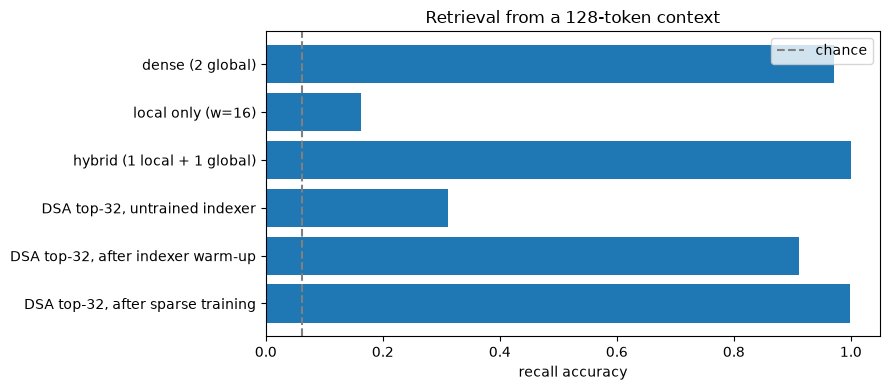

In [6]:
plt.figure(figsize=(9, 4))
plt.barh(list(results)[::-1], list(results.values())[::-1], color="C0")
plt.axvline(1 / NV, ls="--", c="gray", label="chance"); plt.xlabel("recall accuracy"); plt.legend(); plt.title(f"Retrieval from a {T_ctx}-token context"); plt.tight_layout(); plt.show()

## What the indexer selects
For the final query token, which keys did each layer's indexer pick? A good indexer in the retrieval layer includes the matching key–value pair, far back in the context, among its top-$k$.

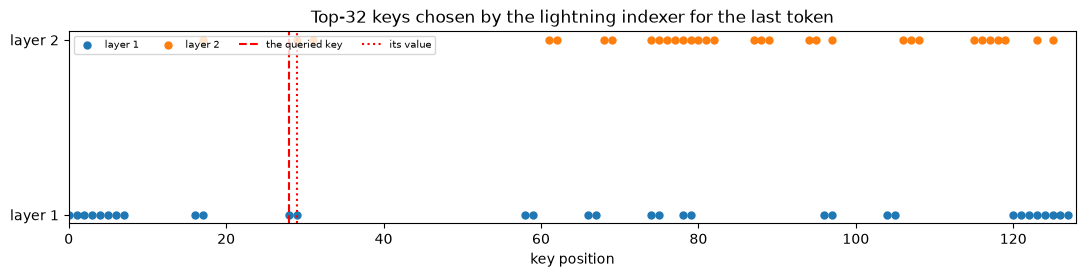

keys attended per query: dense up to 128, DSA 32  ->  core-attention work cut by ~4x at this length (and ~62x at 128K with k=2048)


In [7]:
x, y = batch(1); dsa.eval()
with torch.no_grad():
    h = dsa.emb(x); picks = []
    for a, m, n1, n2 in zip(dsa.attn, dsa.mlp, dsa.n1, dsa.n2):
        idx = a.indexer(n1(h))[0, -1]                                   # scores of the last query token
        picks.append(idx.topk(32).indices.cpu()); h = h + a(n1(h)); h = h + m(n2(h))
target_pos = (x[0, : T_ctx - 2 * NQ] == x[0, -1]).nonzero().item()      # where the last queried key sits in the context
fig, ax = plt.subplots(figsize=(13, 2.5))
for l, p in enumerate(picks): ax.scatter(p, [l] * len(p), s=25, label=f"layer {l + 1}")
ax.axvline(target_pos, c="r", ls="--", label="the queried key"); ax.axvline(target_pos + 1, c="r", ls=":", label="its value")
ax.set(xlabel="key position", yticks=range(2), yticklabels=[f"layer {i + 1}" for i in range(2)], xlim=(0, T_ctx))
ax.legend(fontsize=7, ncol=5, loc="upper left"); plt.title("Top-32 keys chosen by the lightning indexer for the last token"); plt.show()
print(f"keys attended per query: dense up to {T_ctx}, DSA {32}  ->  core-attention work cut by ~{T_ctx / 32:.0f}x at this length (and ~{128_000 // 2048}x at 128K with k=2048)")

## Takeaways
- **Local-only** attention can't retrieve beyond its window, no matter how it is trained. One global layer (**hybrid**) restores retrieval while most layers stay cheap.
- **DSA** keeps most of the dense model's accuracy (close to it, run to run) with only $k$ keys per query, as long as the indexer is first trained to imitate dense attention. Picking keys with an untrained indexer breaks the model. At this toy length $k$ is a quarter of the context; at 128K tokens, DeepSeek's $k=2048$ is under 2%.
- The 2026 long-context recipe stacks these ideas: sparse or linear global layers, local layers, MLA-style compressed caches (67) and very sparse MoE (64).